#import libraries

In [1]:
import numpy as np  
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import os
from sklearn.base import clone
from skimage.feature import local_binary_pattern
from collections import Counter
from sklearn.model_selection import train_test_split , StratifiedKFold ,cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.metrics import (classification_report, accuracy_score , confusion_matrix , 
                             ConfusionMatrixDisplay , roc_curve, auc , roc_auc_score, 
                             RocCurveDisplay , PrecisionRecallDisplay ,  recall_score, 
                             precision_score, f1_score)
from sklearn.ensemble import  VotingClassifier
from xgboost import XGBClassifier 
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
import joblib

#Loading dataset's images

In [2]:
image_path = "dataset/normal/" + os.listdir("dataset/normal")[0]
image = cv2.imread(image_path)
print(f"Image shape: {image.shape}")

dataset_path = "dataset"
sizes = []
for class_name in ["normal", "Oral Cancer photos"]:
    class_path = os.path.join(dataset_path, class_name)
    for filename in os.listdir(class_path):
        image_path = os.path.join(class_path, filename)
        image = cv2.imread(image_path)
        if image is not None:
            height, width = image.shape[:2]
            sizes.append((width, height))

print("Total valid images:", len(sizes))
size_counts = Counter(sizes)
print("\nNumber of different image sizes:", len(size_counts))
print("\nMost common sizes:")
for size, count in size_counts.most_common(20):
    print(size, "-->", count)

Image shape: (126, 144, 3)
Total valid images: 1238

Number of different image sizes: 932

Most common sizes:
(280, 205) --> 39
(960, 1280) --> 30
(468, 1040) --> 18
(720, 1280) --> 13
(275, 183) --> 12
(1800, 4000) --> 10
(500, 333) --> 10
(1100, 618) --> 9
(225, 225) --> 7
(500, 375) --> 6
(1280, 720) --> 5
(274, 184) --> 5
(1280, 1280) --> 5
(1280, 960) --> 5
(620, 415) --> 5
(1105, 950) --> 5
(1280, 719) --> 5
(720, 415) --> 4
(600, 400) --> 4
(3024, 4032) --> 4


##frequent image sizes

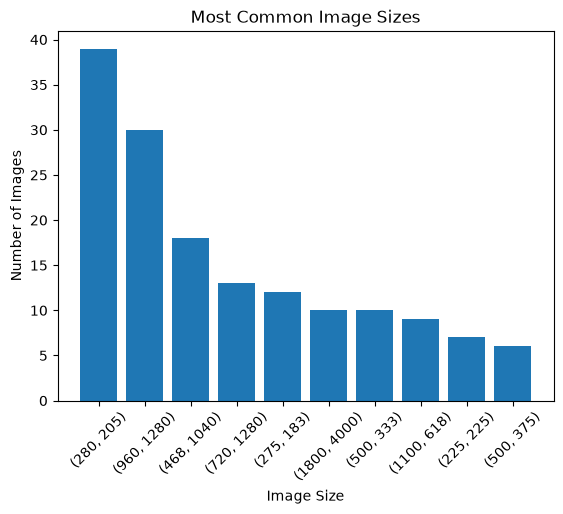

In [3]:
top_sizes = size_counts.most_common(10)

labels = []
counts = []

for size, count in top_sizes:
    labels.append(str(size))
    counts.append(count)

plt.bar(labels, counts)
plt.title("Most Common Image Sizes")
plt.xlabel("Image Size")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

##Image width histogram

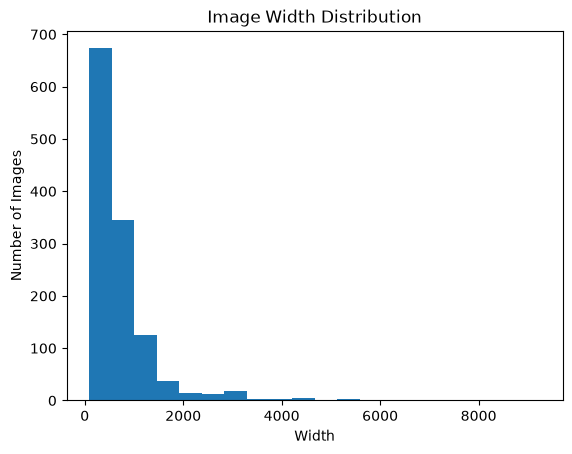

In [4]:
widths = []

for width, height in sizes:
    widths.append(width)

plt.hist(widths, bins=20)
plt.title("Image Width Distribution")
plt.xlabel("Width")
plt.ylabel("Number of Images")
plt.show()

##Image height histogram

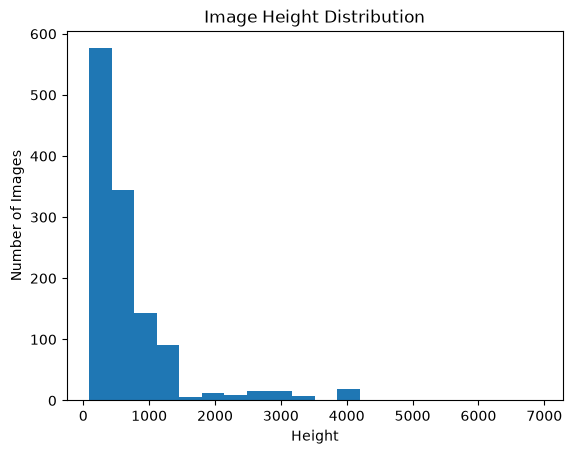

In [5]:
heights = []

for width, height in sizes:
    heights.append(height)

plt.hist(heights, bins=20)
plt.title("Image Height Distribution")
plt.xlabel("Height")
plt.ylabel("Number of Images")
plt.show()

#showing and Resizing Images

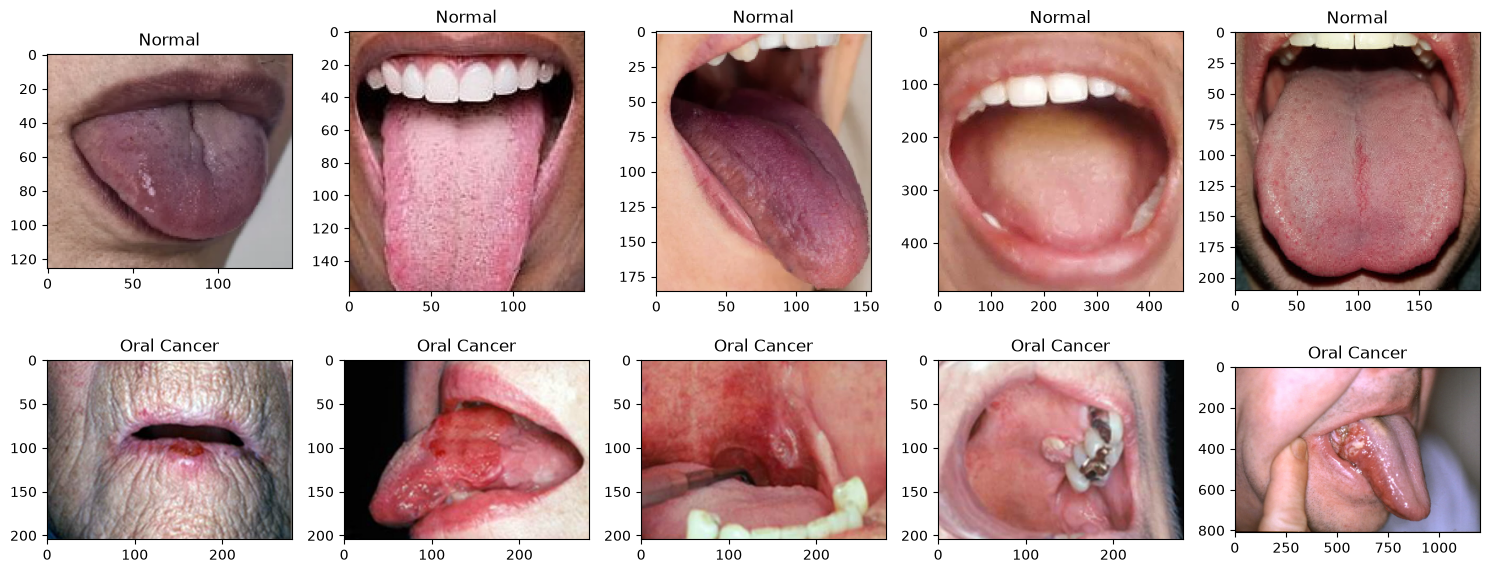

In [6]:

dataset_path = "dataset"

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

# Normal
normal_path = os.path.join(dataset_path, "normal")
normal_files = os.listdir(normal_path)

for i in range(5):
    image_path = os.path.join(normal_path, normal_files[i])
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    axes[0, i].imshow(image)
    axes[0, i].set_title("Normal")


# Oral Cancer
cancer_path = os.path.join(dataset_path, "Oral Cancer photos")
cancer_files = os.listdir(cancer_path)

for i in range(5):
    image_path = os.path.join(cancer_path, cancer_files[i])
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    axes[1, i].imshow(image)
    axes[1, i].set_title("Oral Cancer")


plt.tight_layout()
plt.show()

#Resizing images

In [7]:

for class_name in ["normal", "Oral Cancer photos"]:
    input_folder = "dataset/" + class_name
    output_folder = "dataset_128/" + class_name
    os.makedirs(output_folder, exist_ok=True)
    for filename in os.listdir(input_folder):
        if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
            continue
        image_path = input_folder + "/" + filename
        image = cv2.imread(image_path)
        if image is None:
            continue
    
        rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        resized = cv2.resize(image, (128, 128))
        output_path = output_folder + "/" + filename
        cv2.imwrite(output_path, resized)


#Convert to Gray

In [8]:
for class_name in ["normal", "Oral Cancer photos"]:
    input_folder = "dataset_128/" + class_name
    output_folder = "dataset_gray/" + class_name
    os.makedirs(output_folder, exist_ok=True)
    for filename in os.listdir(input_folder):
        if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
            continue
        image_path = input_folder + "/" + filename
        image = cv2.imread(image_path)
        if image is None:
            continue
        # BGR to Gray
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        output_path = output_folder + "/" + filename
        cv2.imwrite(output_path, gray)


#HOG and LBP

In [9]:

hog = cv2.HOGDescriptor(
    (128, 128),
    (16, 16),
    (8, 8),
    (8, 8),
    9
)

P = 8
R = 1

X_HOG = []
X_LBP = []
y = []

for class_name, label in [
    ("normal", 0),
    ("Oral Cancer photos", 1)
]:
    folder = os.path.join("dataset_gray", class_name)

    for filename in sorted(os.listdir(folder)):
        if not filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):
            continue

        image_path = os.path.join(folder, filename)
        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

        if image is None:
            continue

        image = cv2.resize(image, (128, 128))

        # HOG features
        hog_features = hog.compute(image).flatten()

        # LBP features
        lbp = local_binary_pattern(
            image, P, R, method="uniform"
        )

        hist, _ = np.histogram(
            lbp.ravel(),
            bins=np.arange(0, P + 3),
            range=(0, P + 2)
        )

        hist = hist.astype("float32")
        hist /= hist.sum() + 1e-7

        # Both feature sets belong to the same image
        X_HOG.append(hog_features)
        X_LBP.append(hist)
        y.append(label)

X_HOG = np.asarray(X_HOG)
X_LBP = np.asarray(X_LBP)
y = np.asarray(y)

X_HOG_LBP = np.hstack((X_HOG, X_LBP))

print("HOG shape:", X_HOG.shape)
print("LBP shape:", X_LBP.shape)
print("Combined shape:", X_HOG_LBP.shape)
print("Labels shape:", y.shape)
print("Class counts:", np.bincount(y))


HOG shape: (1233, 8100)
LBP shape: (1233, 10)
Combined shape: (1233, 8110)
Labels shape: (1233,)
Class counts: [551 682]


#Train and Test split

In [10]:
X_Train , X_Test , y_Train , y_Test= train_test_split(X_HOG_LBP , 
                                                      y,
                                                      test_size=0.2,
                                                      random_state= 42,
                                                      stratify= y )
print(f"X_Traine : {X_Train.shape}")
print(f"X_Test: {X_Test.shape}")
print(f"y_Train: {y_Train.shape}")
print(f"y_Test: {y_Test.shape}")

X_Traine : (986, 8110)
X_Test: (247, 8110)
y_Train: (986,)
y_Test: (247,)


#Cross validation

In [11]:
cv = StratifiedKFold(
                     n_splits=5,
                     shuffle=True,
                     random_state=42
                    )

#XGBoost model

In [12]:
clf_XGB = XGBClassifier(
                        n_estimators = 200,
                        max_depth = 3,
                        learning_rate = 0.1,
                        reg_alpha = 0.1,
                        reg_lambda = 5,
                        subsample = 0.8,
                        colsample_bytree = 0.8,
                        random_state = 42,
                        eval_metric="logloss",
                        n_jobs=-1
)

cv_scores_XGB = cross_val_score(
    clf_XGB,
    X_Train,
    y_Train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

clf_XGB.fit(X_Train, y_Train)

y_pred_test = clf_XGB.predict(X_Test)

acc_score = accuracy_score(y_Test, y_pred_test)

clf_report = classification_report(y_Test, y_pred_test, target_names=["Normal", "Oral Cancer"])

cm_XGB = confusion_matrix(y_Test, y_pred_test)

print(f"XGBoost ، Accuracy: {acc_score:.4f}")
print(f"Classification Report: {clf_report}")
print(f"confusion_matrix: {cm_XGB}")

print("CV F1-macro scores:", cv_scores_XGB)
print("Mean CV F1-macro:", cv_scores_XGB.mean())
print("Std CV F1-macro:", cv_scores_XGB.std())

XGBoost ، Accuracy: 0.8097
Classification Report:               precision    recall  f1-score   support

      Normal       0.84      0.71      0.77       110
 Oral Cancer       0.79      0.89      0.84       137

    accuracy                           0.81       247
   macro avg       0.82      0.80      0.80       247
weighted avg       0.81      0.81      0.81       247

confusion_matrix: [[ 78  32]
 [ 15 122]]
CV F1-macro scores: [0.80779221 0.79543094 0.81918548 0.84827238 0.78064687]
Mean CV F1-macro: 0.810265577769453
Std CV F1-macro: 0.02292393293903255


##Confusion matrix for XGBoost

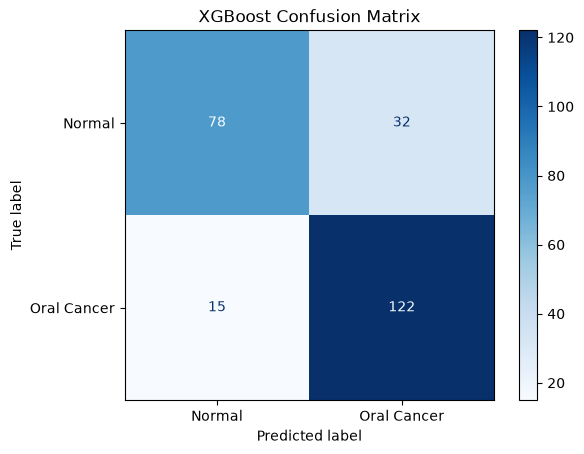

In [13]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_XGB,
                              display_labels=["Normal", "Oral Cancer"])

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("XGBoost Confusion Matrix")
plt.show()
plt.show()

##Feature importance for XGBoost

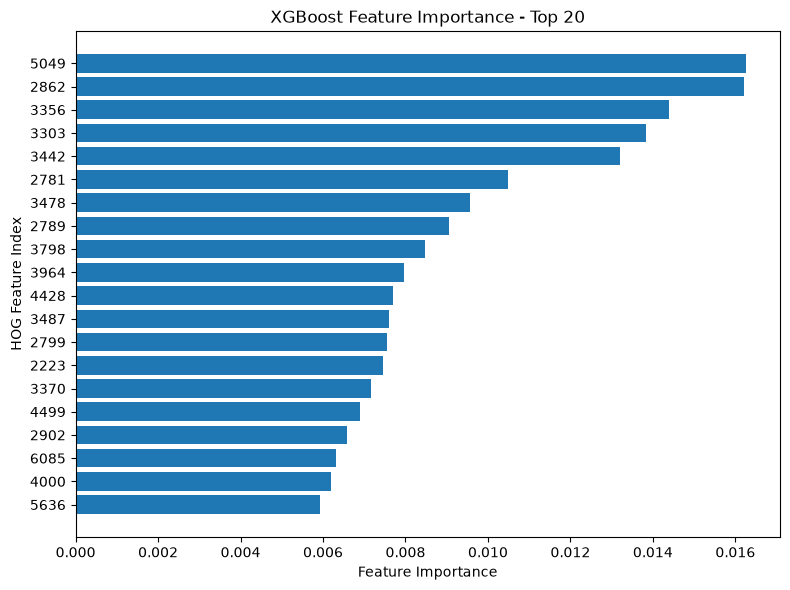

In [14]:
importances = clf_XGB.feature_importances_

indices = np.argsort(importances)[-20:]

plt.figure(figsize=(8, 6))

plt.barh(
    range(len(indices)),
    importances[indices]
)

plt.yticks(
    range(len(indices)),
    indices
)

plt.xlabel("Feature Importance")
plt.ylabel("HOG Feature Index")
plt.title("XGBoost Feature Importance - Top 20")

plt.tight_layout()
plt.show()

##ROC for XGBoost

XGBoost ROC-AUC: 0.8878


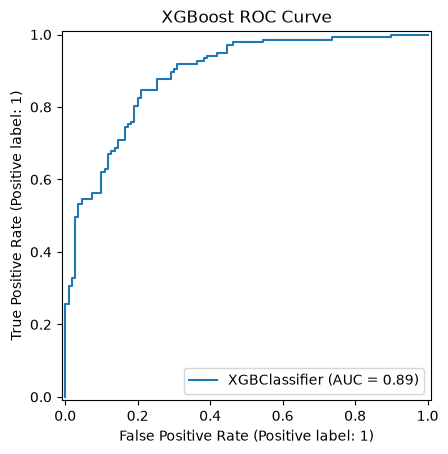

In [15]:
y_score_XGB = clf_XGB.predict_proba(X_Test)[:, 1]
AUC_XGB = roc_auc_score(y_Test, y_score_XGB)

RocCurveDisplay.from_estimator(clf_XGB, X_Test, y_Test)
print(f"XGBoost ROC-AUC: {AUC_XGB:.4f}")
plt.title("XGBoost ROC Curve")
plt.show()

##Precision for XGBoost

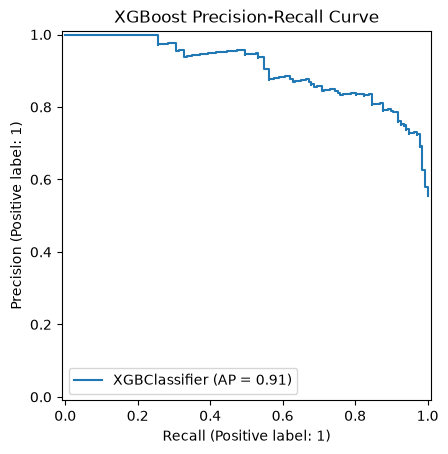

In [16]:
PrecisionRecallDisplay.from_estimator(clf_XGB, X_Test, y_Test)

plt.title("XGBoost Precision-Recall Curve")
plt.show()

#SVM Model

In [17]:
clf_SVM= SVC( 
             C=1,
             gamma="scale",
             kernel="rbf",
             class_weight="balanced",
             probability=True,
             random_state=42,
             )

pipeline_svm = Pipeline([("scaler", StandardScaler()), ("model",clf_SVM)])

cv_scores_SVM = cross_val_score(
    pipeline_svm,
    X_Train,
    y_Train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

pipeline_svm.fit(X_Train , y_Train)

y_pred_test = pipeline_svm.predict(X_Test)

acc_score = accuracy_score(y_Test, y_pred_test)

clf_report = classification_report(y_Test, y_pred_test, target_names=["Normal", "Oral Cancer"])

cm_SVM = confusion_matrix(y_Test, y_pred_test)

print(f"SVM Test Accuracy: {acc_score:.4f}")
print(f"Classification Report:\n{clf_report}")
print(f"confusion_matrix: {cm_SVM}")

print("CV F1-macro scores:", cv_scores_SVM)
print("Mean CV F1-macro:", cv_scores_SVM.mean())
print("Std CV F1-macro:", cv_scores_SVM.std())



c:\Users\MY HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM Test Accuracy: 0.8219
Classification Report:
              precision    recall  f1-score   support

      Normal       0.87      0.71      0.78       110
 Oral Cancer       0.80      0.91      0.85       137

    accuracy                           0.82       247
   macro avg       0.83      0.81      0.82       247
weighted avg       0.83      0.82      0.82       247

confusion_matrix: [[ 78  32]
 [ 12 125]]
CV F1-macro scores: [0.82857143 0.84026888 0.8372031  0.8471029  0.81619705]
Mean CV F1-macro: 0.8338686729285169
Std CV F1-macro: 0.010654322180030668


##confusion matrix for SVM

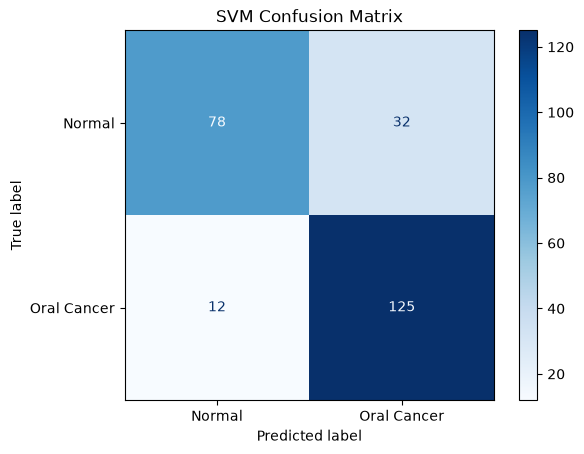

In [18]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_SVM,
                              display_labels=["Normal", "Oral Cancer"])

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("SVM Confusion Matrix")
plt.show()
plt.show()

##ROC for SVM

SVM ROC-AUC: 0.8647


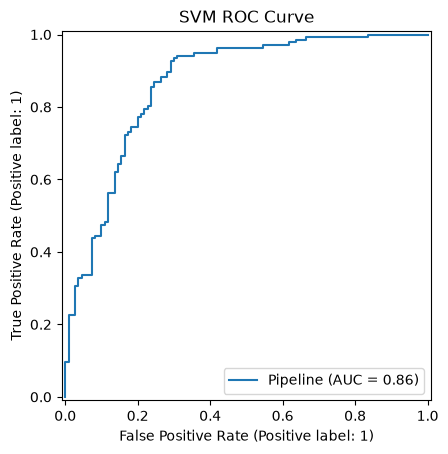

In [19]:
y_score_SVM = pipeline_svm.decision_function(X_Test)

auc_SVM = roc_auc_score(y_Test, y_score_SVM)

print(f"SVM ROC-AUC: {auc_SVM:.4f}")

RocCurveDisplay.from_estimator( pipeline_svm , X_Test , y_Test)

plt.title("SVM ROC Curve")
plt.show()

##Precision for SVM

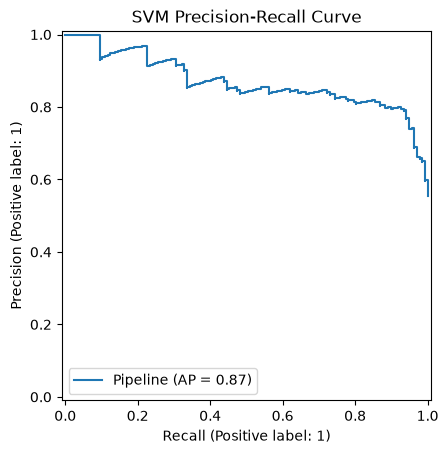

In [20]:
PrecisionRecallDisplay.from_estimator(
    pipeline_svm,
    X_Test,
    y_Test
)

plt.title("SVM Precision-Recall Curve")
plt.show()

#MLP

In [21]:
clf_MLP= MLPClassifier(
                        hidden_layer_sizes = (256, 128, 64, 32 , 16 , 8 , 4 , 2),
                        activation= "relu", 
                        solver= "adam",
                        alpha= 0.001,
                        max_iter=5000,
                        early_stopping=True,
                        n_iter_no_change=100,
                        random_state=42
                        )



pipeline_MLP = Pipeline([("scaler", StandardScaler()) , ("model", clf_MLP)])

cv_scores_MLP = cross_val_score(
    pipeline_MLP,
    X_Train,
    y_Train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

pipeline_MLP.fit(X_Train, y_Train)

y_pred_MLP = pipeline_MLP.predict(X_Test)

acc_score = accuracy_score(y_Test, y_pred_MLP)

clf_report =classification_report(y_Test,y_pred_MLP,target_names=["Normal", "Oral Cancer"])

cm_MLP = confusion_matrix(y_Test, y_pred_MLP)


print(f"MLP Test Accuracy: {acc_score:.4f}")
print(f"Classification Report:\n{clf_report}")
print(f"confusion_matrix: {cm_MLP}")

print("CV F1-macro scores:", cv_scores_MLP)
print("Mean CV F1-macro:", cv_scores_MLP.mean())
print("Std CV F1-macro:", cv_scores_MLP.std())



MLP Test Accuracy: 0.7854
Classification Report:
              precision    recall  f1-score   support

      Normal       0.75      0.77      0.76       110
 Oral Cancer       0.81      0.80      0.80       137

    accuracy                           0.79       247
   macro avg       0.78      0.78      0.78       247
weighted avg       0.79      0.79      0.79       247

confusion_matrix: [[ 85  25]
 [ 28 109]]
CV F1-macro scores: [0.80843553 0.78163586 0.8126189  0.87420179 0.79923836]
Mean CV F1-macro: 0.8152260876652555
Std CV F1-macro: 0.03135268089822687


##confusion matrix for MLP

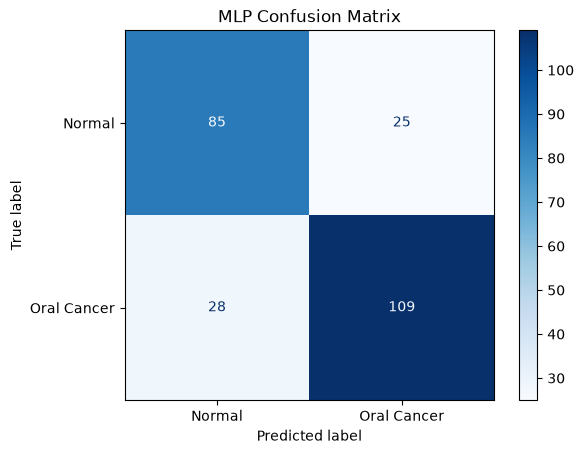

In [22]:
disp = ConfusionMatrixDisplay(confusion_matrix= cm_MLP,
                              display_labels=["Normal", "Oral Cancer"])

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("MLP Confusion Matrix")
plt.show()
plt.show()

##ROC for MLP

MLP ROC-AUC: 0.8648


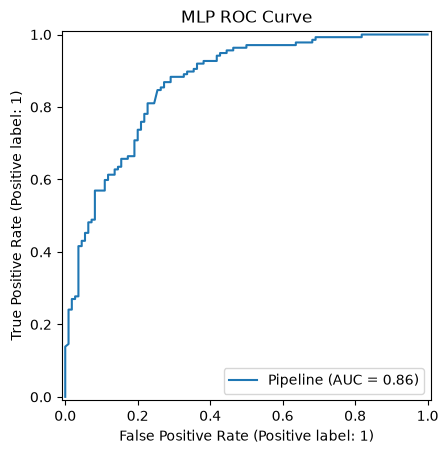

In [23]:
y_score_MLP = pipeline_MLP.predict_proba(X_Test)[:, 1]

auc_MLP = roc_auc_score(y_Test, y_score_MLP)

print(f"MLP ROC-AUC: {auc_MLP:.4f}")

RocCurveDisplay.from_estimator( pipeline_MLP , X_Test , y_Test)

plt.title("MLP ROC Curve")
plt.show()

##PrecisionRecall for MLP

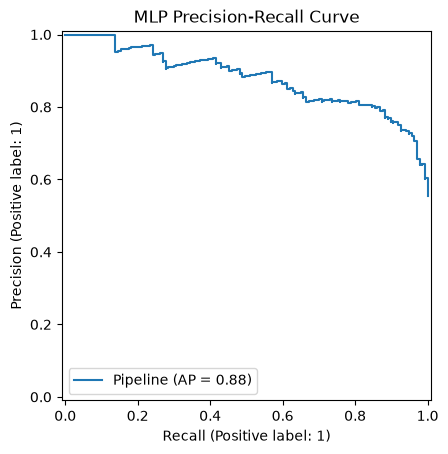

In [24]:
PrecisionRecallDisplay.from_estimator(pipeline_MLP, X_Test, y_Test)

plt.title("MLP Precision-Recall Curve")
plt.show()

#voting

In [25]:
voting_final = VotingClassifier(
    estimators=[
        ("svm", pipeline_svm),
        ("xgb", clf_XGB),
        ("mlp", pipeline_MLP)
    ],
    voting="soft",
    weights=[2, 1, 1],
    n_jobs=-1
)

cv_scores_voting = cross_val_score(
    voting_final,
    X_Train,
    y_Train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)
voting_final.fit(X_Train, y_Train)

#y_pred_final = voting_final.predict(X_Test)      # for threshold 0.5
y_prob_final = voting_final.predict_proba(X_Test)[:, 1]

threshold = 0.4
y_pred_final = (y_prob_final >= threshold).astype(int)

acc_score = accuracy_score(y_Test, y_pred_final)
clf_report = classification_report(y_Test, y_pred_final)
cm_voting = confusion_matrix(y_Test, y_pred_final)

print(f"Accuracy:{acc_score}")
print(f"Classification Report:\n{clf_report}")     
print(f"Confusion Matrix:\n {cm_voting}")
print("ROC-AUC:", roc_auc_score(y_Test, y_prob_final))

print("CV F1-macro scores:", cv_scores_voting)
print("Mean CV F1-macro:", cv_scores_voting.mean())
print("Std CV F1-macro:", cv_scores_voting.std())

Accuracy:0.8299595141700404
Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.70      0.79       110
           1       0.80      0.93      0.86       137

    accuracy                           0.83       247
   macro avg       0.85      0.82      0.82       247
weighted avg       0.84      0.83      0.83       247

Confusion Matrix:
 [[ 77  33]
 [  9 128]]
ROC-AUC: 0.8771068347710683
CV F1-macro scores: [0.83950004 0.82083929 0.83287381 0.86319444 0.79595251]
Mean CV F1-macro: 0.8304720184888945
Std CV F1-macro: 0.022101658809624624


##confusion matrix for final voting

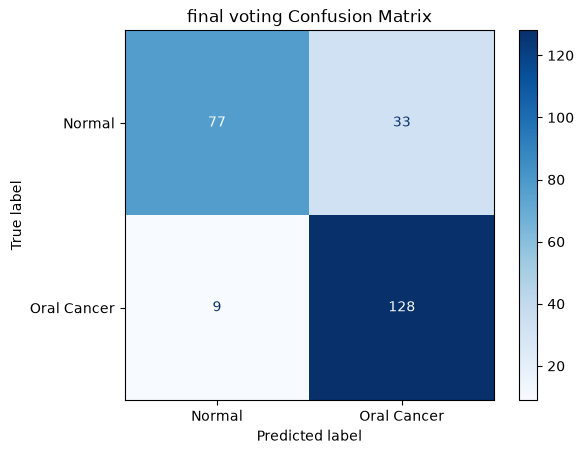

In [26]:
disp = ConfusionMatrixDisplay(confusion_matrix= cm_voting,
                              display_labels=["Normal", "Oral Cancer"])

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("final voting Confusion Matrix")
plt.show()
plt.show()

##ROC for  final votting

final voting ROC-AUC: 0.8771


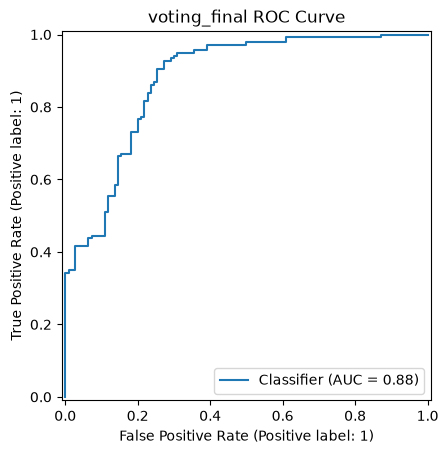

In [27]:
y_score_voting_final = voting_final.predict_proba(X_Test)[:, 1]

auc_voting_fianl = roc_auc_score(y_Test, y_score_voting_final)

print(f"final voting ROC-AUC: {auc_voting_fianl:.4f}")

RocCurveDisplay.from_predictions( y_Test, y_score_voting_final)

plt.title("voting_final ROC Curve")
plt.show()

##PrecisionRecall for final voting

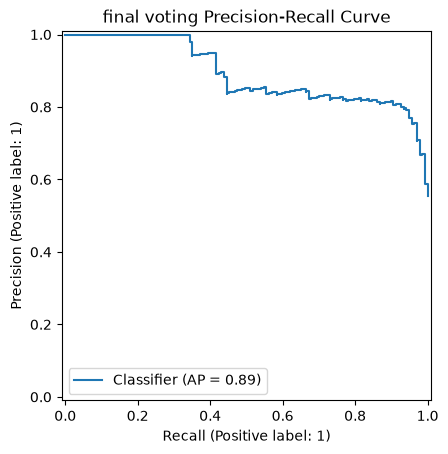

In [28]:
PrecisionRecallDisplay.from_predictions( y_Test, y_score_voting_final)

plt.title("final voting Precision-Recall Curve")
plt.show()

#Comparing of models' accuracy 

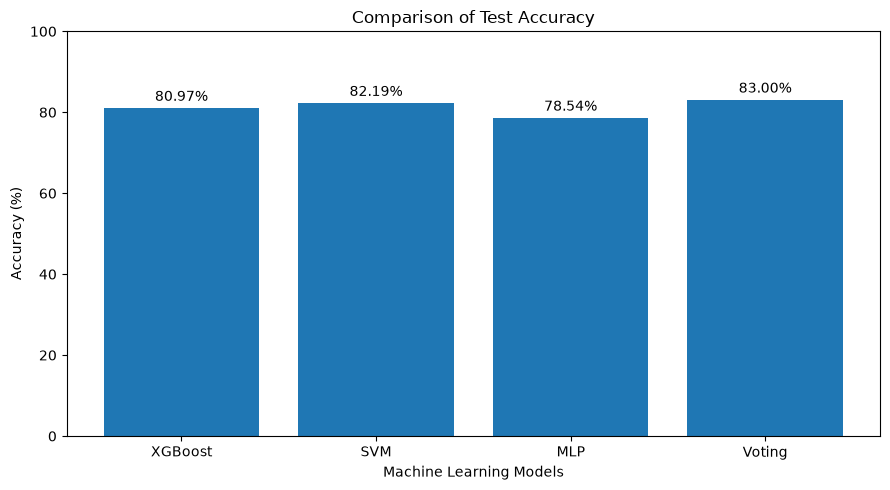

In [29]:
models = ["XGBoost", "SVM", "MLP", "Voting"]

accuracy = [80.97, 82.19, 78.54, 83.00]

plt.figure(figsize=(9, 5))

bars = plt.bar(models, accuracy)

plt.title("Comparison of Test Accuracy")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()


#Comparing of models' precision, recall and f1_score

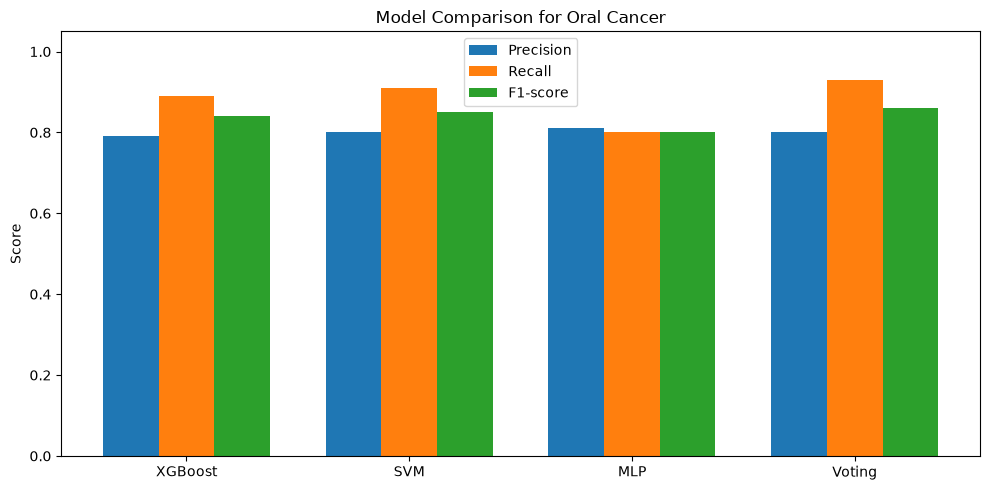

In [30]:
models = ["XGBoost", "SVM", "MLP", "Voting"]

precision = [0.79, 0.80, 0.81, 0.80]
recall    = [0.89, 0.91, 0.80, 0.93]
f1_score  = [0.84, 0.85, 0.80, 0.86]

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(10, 5))

plt.bar(x - width, precision, width, label="Precision")
plt.bar(x, recall, width, label="Recall")
plt.bar(x + width, f1_score, width, label="F1-score")

plt.xticks(x, models)
plt.ylabel("Score")
plt.title("Model Comparison for Oral Cancer")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()


#Comparing of models' mean_f1 and std_f1

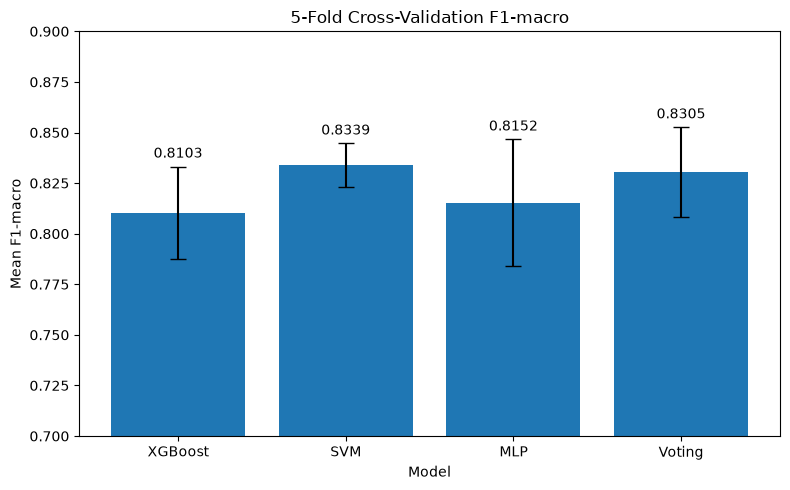

In [31]:
models = ["XGBoost", "SVM", "MLP", "Voting"]
mean_f1 = [0.8103 , 0.8339 , 0.8152 , 0.8305]
std_f1 = [0.0229 , 0.0107 , 0.0314 , 0.0221]

plt.figure(figsize=(8, 5))

bars = plt.bar(models, mean_f1, yerr=std_f1, capsize=6)

plt.title("5-Fold Cross-Validation F1-macro")
plt.xlabel("Model")
plt.ylabel("Mean F1-macro")
plt.ylim(0.70, 0.90)
plt.bar_label(bars, fmt="%.4f", padding=4)

plt.tight_layout()
plt.show()


#Saving model

In [32]:
joblib.dump(voting_final, "oral_cancer_voting_model.pkl")
print("Model saved successfully!")

Model saved successfully!


In [33]:
folder = r"C:\Users\MY HP\Desktop\Oral Cancerrr"

images = [
    f for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
]

print("Number of images:", len(images))
print(images[:10])

Number of images: 1
['Untitled.jpg']


In [34]:
#model = joblib.load("oral_cancer_voting_model.pkl")

#image_path = os.path.join(folder, images[0])

#image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
#image = cv2.resize(image, (128, 128))

#features = hog.compute(image).flatten()
#prediction = model.predict(features.reshape(1, -1))

#if prediction == 0:
#    print("Prediction: Normal")
#else:
#    print("Prediction: Oral Cancer")

#print("Image:", image_path)

In [35]:
model = joblib.load("oral_cancer_voting_model.pkl")

image_path = r"C:\Users\MY HP\Desktop\Oral Cancerrr\Untitled.jpg"

image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if image is None:
    print("Image not found!")
else:
    image = cv2.resize(image, (128, 128))

    # HOG features
    hog_features = hog.compute(image).flatten()

    # LBP features
    lbp = local_binary_pattern(
        image, 8, 1, method="uniform"
    )

    hist, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(0, 11),
        range=(0, 10)
    )

    hist = hist.astype("float32")
    hist /= hist.sum() + 1e-7

    # Combine HOG and LBP
    features = np.hstack((hog_features, hist))

    print("Number of features:", len(features))

    # Prediction
    probabilities = model.predict_proba(
        features.reshape(1, -1)
    )[0]

    threshold = 0.4
    prediction = int(probabilities[1] >= threshold)

    print("Normal probability:", round(probabilities[0] * 100, 2), "%")
    print("Oral Cancer probability:", round(probabilities[1] * 100, 2), "%")

    if prediction == 0:
        print("Prediction: Normal")
    else:
        print("Prediction: Oral Cancer")


Number of features: 8110
Normal probability: 6.85 %
Oral Cancer probability: 93.15 %
Prediction: Oral Cancer
